* **Problema:** Diagnóstico de fallas en rodamientos industriales mediante señales de vibración.
* **Diámetro de falla:** Estandarizado exclusivamente en **0.007 pulgadas**.
* **Cargas operativas:** Inclusión de los **4 niveles de carga** (0, 1, 2 y 3 HP) para todas las clases.
* **Segmentación de datos:** Corte de señales en **ventanas de 2048 muestras con un 50% de solapamiento**.


In [109]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import urllib.request
import os
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Dropout

In [110]:
from sklearn.preprocessing import StandardScaler

# Inicializamos el escalador
scaler = StandardScaler()

# Ajustamos con Train y transformamos Train, Val y Test
X_train_norm = scaler.fit_transform(X_train)
X_val_norm = scaler.transform(X_val)
X_test_norm = scaler.transform(X_test)

In [111]:
# Mapeo las fuentes para el diámetro 0.007" y las 4 cargas (0, 1, 2, 3 HP)
datasets_config = {
    'Normal': {
        '0HP': 'https://engineering.case.edu/sites/default/files/97.mat',
        '1HP': 'https://engineering.case.edu/sites/default/files/98.mat',
        '2HP': 'https://engineering.case.edu/sites/default/files/99.mat',
        '3HP': 'https://engineering.case.edu/sites/default/files/100.mat'
    },
    'Pista_Interna': {
        '0HP': 'https://engineering.case.edu/sites/default/files/105.mat',
        '1HP': 'https://engineering.case.edu/sites/default/files/106.mat',
        '2HP': 'https://engineering.case.edu/sites/default/files/107.mat',
        '3HP': 'https://engineering.case.edu/sites/default/files/108.mat'
    },
    'Elemento_Rodante': {
        '0HP': 'https://engineering.case.edu/sites/default/files/118.mat',
        '1HP': 'https://engineering.case.edu/sites/default/files/119.mat',
        '2HP': 'https://engineering.case.edu/sites/default/files/120.mat',
        '3HP': 'https://engineering.case.edu/sites/default/files/121.mat'
    },
    'Pista_Externa_6_00': {  # Tomamos la posición @6:00 como referencia principal para la clase de pista externa
        '0HP': 'https://engineering.case.edu/sites/default/files/130.mat',
        '1HP': 'https://engineering.case.edu/sites/default/files/131.mat',
        '2HP': 'https://engineering.case.edu/sites/default/files/132.mat',
        '3HP': 'https://engineering.case.edu/sites/default/files/133.mat'
    }
}

def descargar_y_cargar_mat(url, nombre_local):
    if not os.path.exists(nombre_local):
        print(f"Descargando {nombre_local}...")
        urllib.request.urlretrieve(url, nombre_local)

    mat_data = scipy.io.loadmat(nombre_local)
    # Extraer la clave del acelerador del extremo motor (DE_time)
    clave_de = [k for k in mat_data.keys() if 'DE_time' in k][0]
    return mat_data[clave_de].flatten()

# Diccionario donde guardaremos todas las señales crudas organizadas
seniales_crudas_dataset = {}

for clase, cargas in datasets_config.items():
    seniales_crudas_dataset[clase] = {}
    for carga, url in cargas.items():
        nombre_archivo = f"{clase}_{carga}.mat"
        seniales_crudas_dataset[clase][carga] = descargar_y_cargar_mat(url, nombre_archivo)
        print(f"Cargado -> Clase: {clase} | Carga: {carga} | Muestras: {len(seniales_crudas_dataset[clase][carga])}")

Cargado -> Clase: Normal | Carga: 0HP | Muestras: 243938
Cargado -> Clase: Normal | Carga: 1HP | Muestras: 483903
Cargado -> Clase: Normal | Carga: 2HP | Muestras: 483903
Cargado -> Clase: Normal | Carga: 3HP | Muestras: 485643
Cargado -> Clase: Pista_Interna | Carga: 0HP | Muestras: 121265
Cargado -> Clase: Pista_Interna | Carga: 1HP | Muestras: 121991
Cargado -> Clase: Pista_Interna | Carga: 2HP | Muestras: 122136
Cargado -> Clase: Pista_Interna | Carga: 3HP | Muestras: 122917
Cargado -> Clase: Elemento_Rodante | Carga: 0HP | Muestras: 122571
Cargado -> Clase: Elemento_Rodante | Carga: 1HP | Muestras: 121410
Cargado -> Clase: Elemento_Rodante | Carga: 2HP | Muestras: 121556
Cargado -> Clase: Elemento_Rodante | Carga: 3HP | Muestras: 121556
Cargado -> Clase: Pista_Externa_6_00 | Carga: 0HP | Muestras: 121991
Cargado -> Clase: Pista_Externa_6_00 | Carga: 1HP | Muestras: 122426
Cargado -> Clase: Pista_Externa_6_00 | Carga: 2HP | Muestras: 121410
Cargado -> Clase: Pista_Externa_6_00 | Ca

In [112]:
def segmentar_y_etiquetar(seniales_dict, tamano_ventana=2048, solapamiento=0.5):
    paso = int(tamano_ventana * (1 - solapamiento))
    X = []
    y = []

    # Mapeo de clases a valores numéricos para la red
    clases_mapeo = {
        'Normal': 0,
        'Pista_Interna': 1,
        'Elemento_Rodante': 2,
        'Pista_Externa_6_00': 3
    }

    for clase, cargas in seniales_dict.items():
        etiqueta = clases_mapeo[clase]
        for carga, senial in cargas.items():
            # Recorrer la señal y extraer ventanas
            for i in range(0, len(senial) - tamano_ventana + 1, paso):
                ventana = senial[i:i + tamano_ventana]
                X.append(ventana)
                y.append(etiqueta)

    return np.array(X), np.array(y)

# Ejecutamos la función con nuestro diccionario de señales crudas
X_global, y_global = segmentar_y_etiquetar(seniales_crudas_dataset)

print(f"Dimensiones de X_global (ventanas de datos): {X_global.shape}")
print(f"Dimensiones de y_global (etiquetas): {y_global.shape}")

Dimensiones de X_global (ventanas de datos): (3064, 2048)
Dimensiones de y_global (etiquetas): (3064,)


In [113]:
# 1. Ejecutamos la segmentación con el diccionario de señales crudas
X_global, y_global = segmentar_y_etiquetar(seniales_crudas_dataset)

print(f"Dimensiones de X_global (ventanas de datos): {X_global.shape}")
print(f"Dimensiones de y_global (etiquetas): {y_global.shape}")

# 2. Dividimos los datos asegurando al menos un 20% para el conjunto de prueba (Test)[cite: 3, 30]
from sklearn.model_selection import train_test_split

# Primero separamos Train+Val (80%) y Test (20%) de forma estratificada
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_global, y_global, test_size=0.20, random_state=42, stratify=y_global
)

# Del 80% restante, separamos un porcentaje para Validación (ej. 20% para validación, 60% para entrenamiento neto)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.20, random_state=42, stratify=y_train_val
)

print("\n--- Distribución de los Conjuntos ---")
print(f"Entrenamiento (Train): {X_train.shape[0]} muestras")
print(f"Validación (Val):      {X_val.shape[0]} muestras")
print(f"Prueba (Test):         {X_test.shape[0]} muestras")

Dimensiones de X_global (ventanas de datos): (3064, 2048)
Dimensiones de y_global (etiquetas): (3064,)

--- Distribución de los Conjuntos ---
Entrenamiento (Train): 1960 muestras
Validación (Val):      491 muestras
Prueba (Test):         613 muestras


In [114]:
# Inicializamos el escalador
scaler = StandardScaler()
# Ajustamos con Train y transformamos Train, Val y Test
X_train_norm = scaler.fit_transform(X_train)
X_val_norm = scaler.transform(X_val)
X_test_norm = scaler.transform(X_test)

Datos normalizados correctamente.


# ***1 ARQUITECTURA: Perceptrón Multicapa Profundo***


Epoch 1/25


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.5776 - loss: 1.2792 - val_accuracy: 0.7393 - val_loss: 0.7157
Epoch 2/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7944 - loss: 0.5640 - val_accuracy: 0.8167 - val_loss: 0.4481
Epoch 3/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8765 - loss: 0.3493 - val_accuracy: 0.8615 - val_loss: 0.3665
Epoch 4/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9255 - loss: 0.2346 - val_accuracy: 0.8574 - val_loss: 0.3643
Epoch 5/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9561 - loss: 0.1730 - val_accuracy: 0.8737 - val_loss: 0.3466
Epoch 6/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9556 - loss: 0.1522 - val_accuracy: 0.8635 - val_loss: 0.3706
Epoch 7/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9653 - loss: 0.1139 - val_accuracy: 0.8656 - val_loss: 0.3913
Epoch 8/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9689 - loss: 0.0986 - val_accuracy: 0.8737 - val_loss: 0.4124
Ep

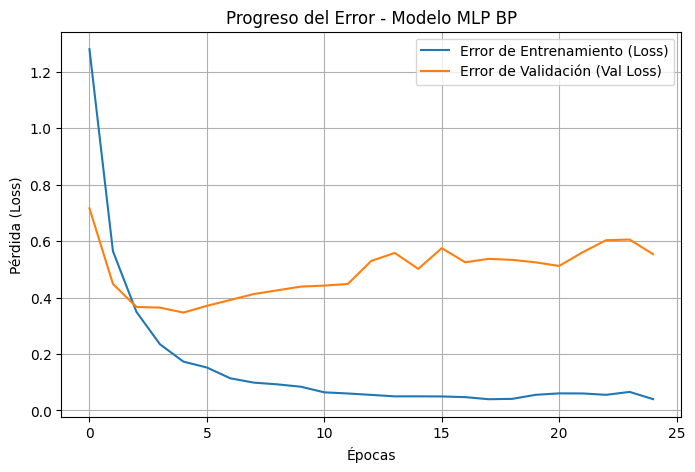

In [115]:
# Construcción de la arquitectura MLP
modelo_mlp = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_norm.shape[1],)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(4, activation='softmax')  # 4 clases de salida (Normal, Pista Interna, Elemento Rodante, Pista Externa)
])

# Compilación del modelo
modelo_mlp.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entrenamiento
historial_mlp = modelo_mlp.fit(
    X_train_norm, y_train,
    validation_data=(X_val_norm, y_val),
    epochs=25,
    batch_size=32
)

# Gráfico del error general (Loss)
plt.figure(figsize=(8, 5))
plt.plot(historial_mlp.history['loss'], label='Error de Entrenamiento (Loss)')
plt.plot(historial_mlp.history['val_loss'], label='Error de Validación (Val Loss)')
plt.title('Progreso del Error - Modelo MLP BP')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.show()

Para evitar el sobreajuste y optimizar el entrenamiento, se configura el mecanismo de Early Stopping especificando una paciencia de tres épocas para detener el proceso automáticamente si la pérdida de validación deja de mejorar.

Epoch 1/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9969 - loss: 0.0138 - val_accuracy: 0.8798 - val_loss: 0.5589
Epoch 2/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9888 - loss: 0.0351 - val_accuracy: 0.8778 - val_loss: 0.5398
Epoch 3/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9980 - loss: 0.0133 - val_accuracy: 0.8880 - val_loss: 0.5535
Epoch 4/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9949 - loss: 0.0290 - val_accuracy: 0.8880 - val_loss: 0.5639
Epoch 5/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9939 - loss: 0.0239 - val_accuracy: 0.8880 - val_loss: 0.5338
Epoch 6/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9944 - loss: 0.0199 - val_accuracy: 0.9022 - val_loss: 0.5237
Epoch 7/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9964 - loss: 0.0137 - val_accuracy: 0.8941 - val_loss: 0.5237
Epoch 8/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9974 - loss: 0.0111 - val_accuracy: 0.9002 - val_loss:

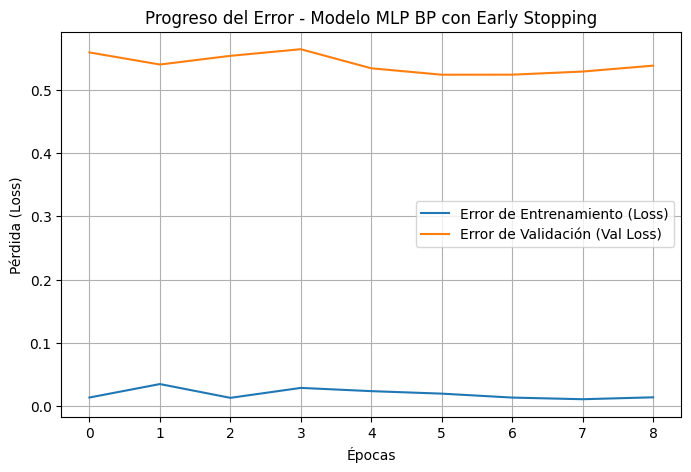

In [116]:
early_stopping = EarlyStopping(
    monitor='val_loss',          # Monitoreamos la pérdida en validación
    patience=3,                  # Número de épocas a esperar si no hay mejora
    restore_best_weights=True    # Restaura los pesos del modelo de la mejor época
)

# Re-entrenamos el modelo MLP incorporando el callback
historial_mlp = modelo_mlp.fit(
    X_train_norm, y_train,
    validation_data=(X_val_norm, y_val),
    epochs=25,
    batch_size=32,
    callbacks=[early_stopping]
)

# Graficamos nuevamente el progreso del error
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(historial_mlp.history['loss'], label='Error de Entrenamiento (Loss)')
plt.plot(historial_mlp.history['val_loss'], label='Error de Validación (Val Loss)')
plt.title('Progreso del Error - Modelo MLP BP con Early Stopping')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.show()

Implementaremos Early Stopping (Parada Temprana).

Esta técnica monitorea el error de validación (val_loss) durante cada época y detiene automáticamente el entrenamiento en el momento exacto en que el modelo deja de mejorar, conservando los mejores pesos obtenidos hasta ese instante.

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


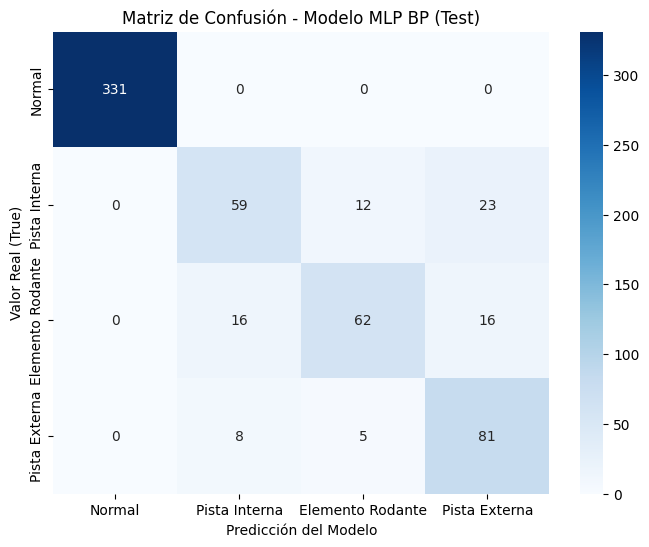

,precision,recall,f1-score,support
Normal,1.000,1.000,1.000,331.000
Pista Interna,0.711,0.628,0.667,94.000
Elemento Rodante,0.785,0.660,0.717,94.000
Pista Externa,0.675,0.862,0.757,94.000
accuracy,0.869,0.869,0.869,0.869
macro avg,0.793,0.787,0.785,613.000
weighted avg,0.873,0.869,0.868,613.000


In [117]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Predecir sobre el conjunto de prueba (Test)
y_pred_probs = modelo_mlp.predict(X_test_norm)
y_pred = np.argmax(y_pred_probs, axis=1)

# 2. Calcular la Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
clases_nombres = ['Normal', 'Pista Interna', 'Elemento Rodante', 'Pista Externa']

# 3. Graficar la Matriz de Confusión
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases_nombres,
            yticklabels=clases_nombres)
plt.title('Matriz de Confusión - Modelo MLP BP (Test)')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (True)')
plt.show()


# 1. Obtenemos el reporte en formato de diccionario
reporte_dict = classification_report(y_test, y_pred, target_names=clases_nombres, output_dict=True)

# 2. Lo convertimos en DataFrame y redondeamos a 3 decimales
df_reporte = pd.DataFrame(reporte_dict).transpose().round(3)

# 3. Mostramos la tabla estilizada
display(df_reporte)

# ***2. ARQUITECTURA:RED NEURONAL CONVOLUCIONAL (CNN)***

In [118]:
# Re-formateamos los datos de entrenamiento, validación y prueba para añadir la dimensión de canal (1)
X_train_cnn = X_train_norm.reshape((X_train_norm.shape[0], X_train_norm.shape[1], 1))
X_val_cnn = X_val_norm.reshape((X_val_norm.shape[0], X_val_norm.shape[1], 1))
X_test_cnn = X_test_norm.reshape((X_test_norm.shape[0], X_test_norm.shape[1], 1))

print(f"Nueva forma de X_train para la CNN: {X_train_cnn.shape}")

Nueva forma de X_train para la CNN: (1960, 2048, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 12s 166ms/step - accuracy: 0.8245 - loss: 0.4293 - val_accuracy: 1.0000 - val_loss: 0.0474
Epoch 2/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 169ms/step - accuracy: 0.9939 - loss: 0.0327 - val_accuracy: 1.0000 - val_loss: 0.0013
Epoch 3/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 20s 160ms/step - accuracy: 0.9995 - loss: 0.0077 - val_accuracy: 1.0000 - val_loss: 6.9807e-04
Epoch 4/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 163ms/step - accuracy: 0.9985 - loss: 0.0053 - val_accuracy: 1.0000 - val_loss: 6.3385e-05
Epoch 5/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 152ms/step - accuracy: 0.9990 - loss: 0.0040 - val_accuracy: 1.0000 - val_loss: 1.1185e-06
Epoch 6/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 147ms/step - accuracy: 0.9990 - loss: 0.0034 - val_accuracy: 1.0000 - val_loss: 2.5349e-06
Epoch 7/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 165ms/step - accuracy: 0.9995 - loss: 0.0033 - val_accuracy: 1.0000 - val_loss: 3.0457e-06
Epoch 8/25
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 164ms/step - accuracy: 0.9995 - loss

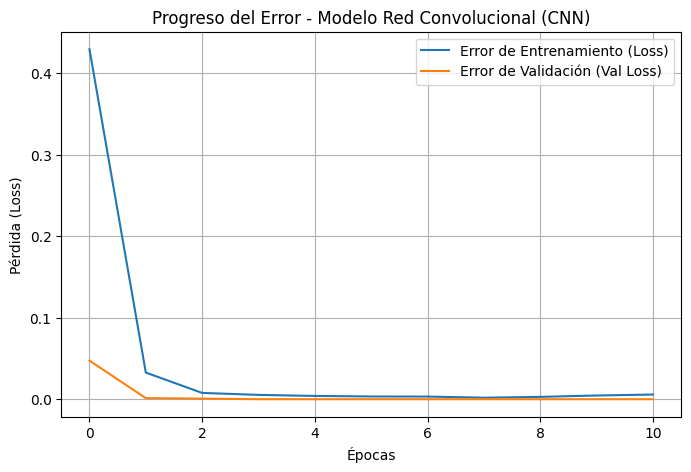

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step

--- Reporte de Clasificación (CNN) ---


,precision,recall,f1-score,support
Normal,1.0,1.0,1.0,331.0
Pista Interna,1.0,1.0,1.0,94.0
Elemento Rodante,1.0,1.0,1.0,94.0
Pista Externa,1.0,1.0,1.0,94.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,613.0
weighted avg,1.0,1.0,1.0,613.0


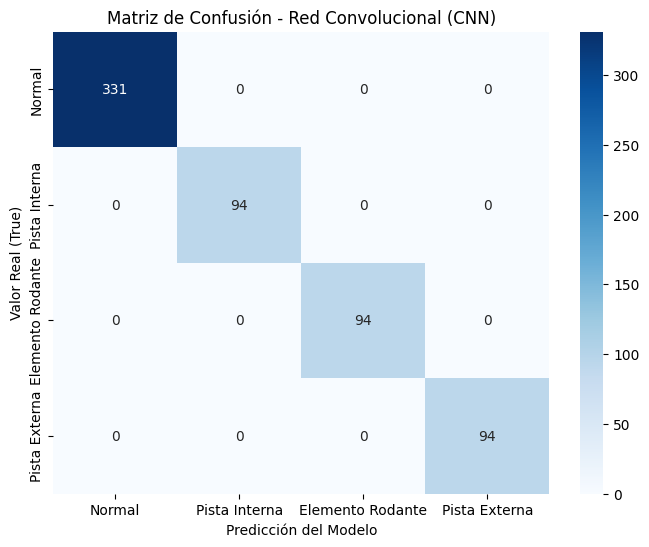

In [123]:
modelo_cnn = Sequential([
    Conv1D(filters=32, kernel_size=5, activation='relu', input_shape=(2048, 1)),
    MaxPooling1D(pool_size=2),

    Conv1D(filters=64, kernel_size=5, activation='relu'),
    MaxPooling1D(pool_size=2),

    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.4),
    Dense(4, activation='softmax')  # 4 clases de salida (Normal, Pista Interna, Elemento Rodante, Pista Externa)
])

# Compilación del modelo
modelo_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Early Stopping para evitar overfitting
early_stopping_cnn = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Entrenamiento
historial_cnn = modelo_cnn.fit(
    X_train_cnn, y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=25,
    batch_size=32,
    callbacks=[early_stopping_cnn]
)

# Gráfico del progreso del error (Loss)
plt.figure(figsize=(8, 5))
plt.plot(historial_cnn.history['loss'], label='Error de Entrenamiento (Loss)')
plt.plot(historial_cnn.history['val_loss'], label='Error de Validación (Val Loss)')
plt.title('Progreso del Error - Modelo Red Convolucional (CNN)')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.show()
# Predicciones con la CNN
y_pred_probs_cnn = modelo_cnn.predict(X_test_cnn)
y_pred_cnn = np.argmax(y_pred_probs_cnn, axis=1)

# Reporte en formato de tabla redondeado a 3 decimales
reporte_dict_cnn = classification_report(y_test, y_pred_cnn, target_names=clases_nombres, output_dict=True)
df_reporte_cnn = pd.DataFrame(reporte_dict_cnn).transpose().round(3)

print("\n--- Reporte de Clasificación (CNN) ---")
display(df_reporte_cnn)

# 2. Calcular la matriz de confusión
cm_cnn = confusion_matrix(y_test, y_pred_cnn)
clases_nombres = ['Normal', 'Pista Interna', 'Elemento Rodante', 'Pista Externa']

# 3. Graficar el mapa de calor (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases_nombres,
            yticklabels=clases_nombres)
plt.title('Matriz de Confusión - Red Convolucional (CNN)')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (True)')
plt.show()

# ***3. ARQUITECTURA: Variante Profunda de MLP (Perceptrón Multicapa Profundo)***




Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.5005 - loss: 1.3398 - val_accuracy: 0.6925 - val_loss: 0.8866
Epoch 2/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7602 - loss: 0.7283 - val_accuracy: 0.8004 - val_loss: 0.4878
Epoch 3/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8327 - loss: 0.4446 - val_accuracy: 0.8350 - val_loss: 0.4824
Epoch 4/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8791 - loss: 0.3350 - val_accuracy: 0.8513 - val_loss: 0.4543
Epoch 5/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9173 - loss: 0.2344 - val_accuracy: 0.8880 - val_loss: 0.3578
Epoch 6/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9388 - loss: 0.1778 - val_accuracy: 0.8880 - val_loss: 0.4317
Epoch 7/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9607 - loss: 0.1287 - val_accuracy: 0.8900 - val_loss: 0.4332
Epoch 8/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9622 - loss: 0.1172 - val_accuracy: 0.8717 - val_loss: 0.

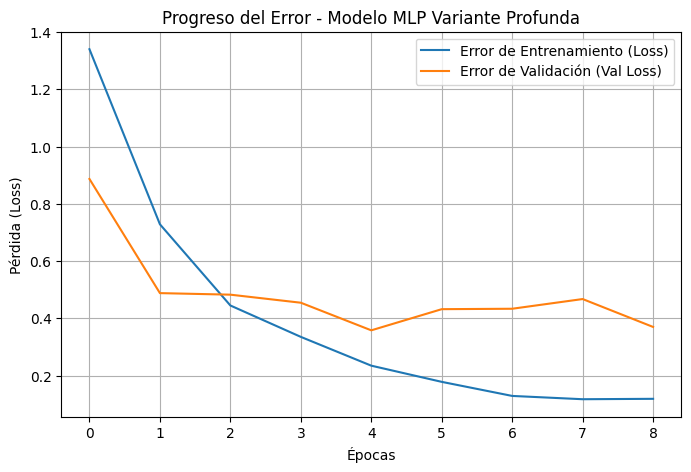


--- Reporte de Clasificación (MLP Variante Profunda) ---


,precision,recall,f1-score,support
Normal,0.997,1.000,0.998,331.000
Pista Interna,0.722,0.606,0.659,94.000
Elemento Rodante,0.714,0.638,0.674,94.000
Pista Externa,0.644,0.809,0.717,94.000
accuracy,0.855,0.855,0.855,0.855
macro avg,0.769,0.763,0.762,613.000
weighted avg,0.857,0.855,0.854,613.000



--- Matriz de Confusión ---


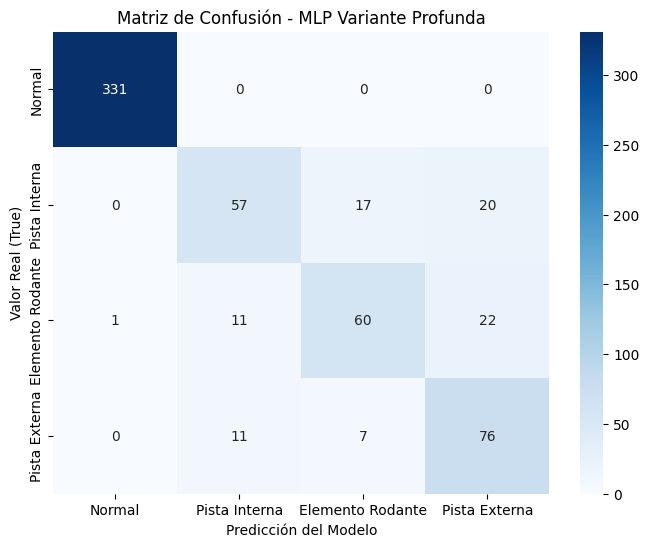

In [126]:
from sklearn.metrics import classification_report

# 1. Construcción de la arquitectura MLP modificada (más profunda)
modelo_mlp_v2 = Sequential([
    Dense(256, activation='relu', input_shape=(X_train_norm.shape[1],)),
    Dropout(0.4),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(4, activation='softmax')  # 4 clases de salida
])

# 2. Compilación del modelo
modelo_mlp_v2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Configuración de Early Stopping con mayor paciencia
early_stopping_v2 = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

# 4. Entrenamiento
historial_mlp_v2 = modelo_mlp_v2.fit(
    X_train_norm, y_train,
    validation_data=(X_val_norm, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping_v2]
)

# 5. Evaluación en el conjunto de Prueba (Test)
y_pred_probs_v2 = modelo_mlp_v2.predict(X_test_norm)
y_pred_v2 = np.argmax(y_pred_probs_v2, axis=1)

# Gráfico del progreso del error (Loss) para la Variante Profunda del MLP
plt.figure(figsize=(8, 5))
plt.plot(historial_mlp_v2.history['loss'], label='Error de Entrenamiento (Loss)')
plt.plot(historial_mlp_v2.history['val_loss'], label='Error de Validación (Val Loss)')
plt.title('Progreso del Error - Modelo MLP Variante Profunda')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.show()

# 6. Reporte en formato de tabla redondeado a 3 decimales
reporte_dict_v2 = classification_report(y_test, y_pred_v2, target_names=clases_nombres, output_dict=True)
df_reporte_v2 = pd.DataFrame(reporte_dict_v2).transpose().round(3)

print("\n--- Reporte de Clasificación (MLP Variante Profunda) ---")
display(df_reporte_v2)

# 7. Matriz de Confusión
print("\n--- Matriz de Confusión ---")
cm_mlp = confusion_matrix(y_test, y_pred_v2)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Blues',
            xticklabels=clases_nombres,
            yticklabels=clases_nombres)
plt.title('Matriz de Confusión - MLP Variante Profunda')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real (True)')
plt.show()